In [10]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import cv2  
import os

data = pd.read_csv("C:/Users/lapto/OneDrive/Desktop/final year project/archive/mimic-cxr.csv")
data

,filename,split,label,Atelectasis,Cardiomegaly,Consolidation,Edema,Enlarged Cardiomediastinum,Lung Lesion,Lung Opacity,Normal,Pleural Effusion,Pneumonia,Pneumothorax
0,s50000014.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,s50000052.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,s50000125.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,s50000173.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,s50000198.jpg,train,Consolidation,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85998,s59930189.jpg,valid,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
85999,s59956973.jpg,valid,Lung Opacity,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
86000,s59969313.jpg,valid,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
86001,s59971654.jpg,valid,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [11]:
# splitting the data into train,valid and test sets 
train_data = data[data['split'] == 'train']
test_data = data[data['split'] == 'test']
valid_data = data[data['split'] == 'valid']


In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86003 entries, 0 to 86002
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   filename                    86003 non-null  object 
 1   split                       86003 non-null  object 
 2   label                       86003 non-null  object 
 3   Atelectasis                 86003 non-null  float64
 4   Cardiomegaly                86003 non-null  float64
 5   Consolidation               86003 non-null  float64
 6   Edema                       86003 non-null  float64
 7   Enlarged Cardiomediastinum  86003 non-null  float64
 8   Lung Lesion                 86003 non-null  float64
 9   Lung Opacity                86003 non-null  float64
 10  Normal                      86003 non-null  float64
 11  Pleural Effusion            86003 non-null  float64
 12  Pneumonia                   86003 non-null  float64
 13  Pneumothorax                860

In [ ]:
train_path = "C:/Users/lapto/OneDrive/Desktop/final year project/archive/train/"
test_path = "C:/Users/lapto/OneDrive/Desktop/final year project/archive/test"
valid_path = "C:/Users/lapto/OneDrive/Desktop/final year project/archive/valid/"

train_data['filename'] = str(train_path + train_data['filename'])
test_data['filename'] = str(test_path + test_data['filename'])
valid_data['filename'] = str(valid_path + valid_data['filename'])
train_data['filename'].head()

C:\Users\lapto\AppData\Local\Temp\ipykernel_16224\1500699808.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data['filename'] = str(train_path + train_data['filename'])
C:\Users\lapto\AppData\Local\Temp\ipykernel_16224\1500699808.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['filename'] = str(test_path + test_data['filename'])
C:\Users\lapto\AppData\Local\Temp\ipykernel_16224\1500699808.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

0    0        C:/Users/lapto/OneDrive/Desktop/final...
1    0        C:/Users/lapto/OneDrive/Desktop/final...
2    0        C:/Users/lapto/OneDrive/Desktop/final...
3    0        C:/Users/lapto/OneDrive/Desktop/final...
4    0        C:/Users/lapto/OneDrive/Desktop/final...
Name: filename, dtype: object

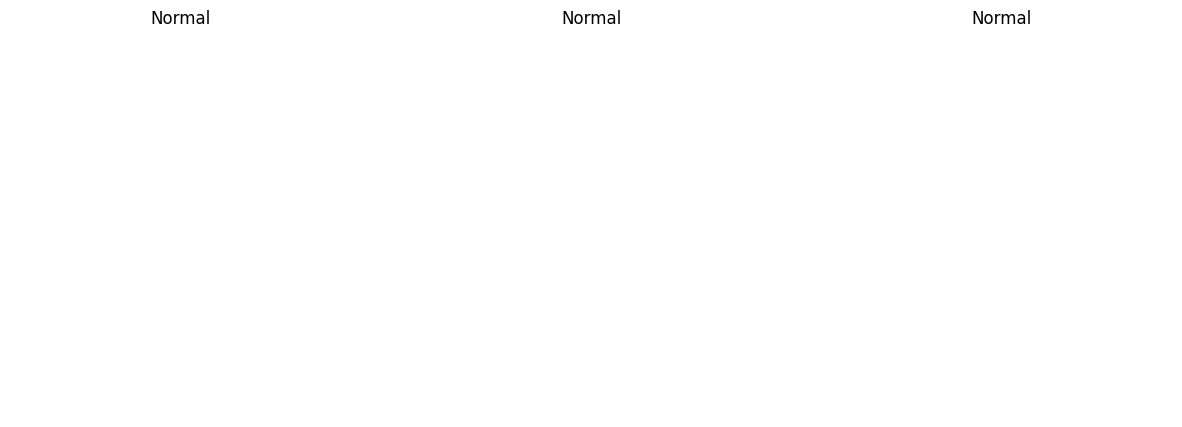

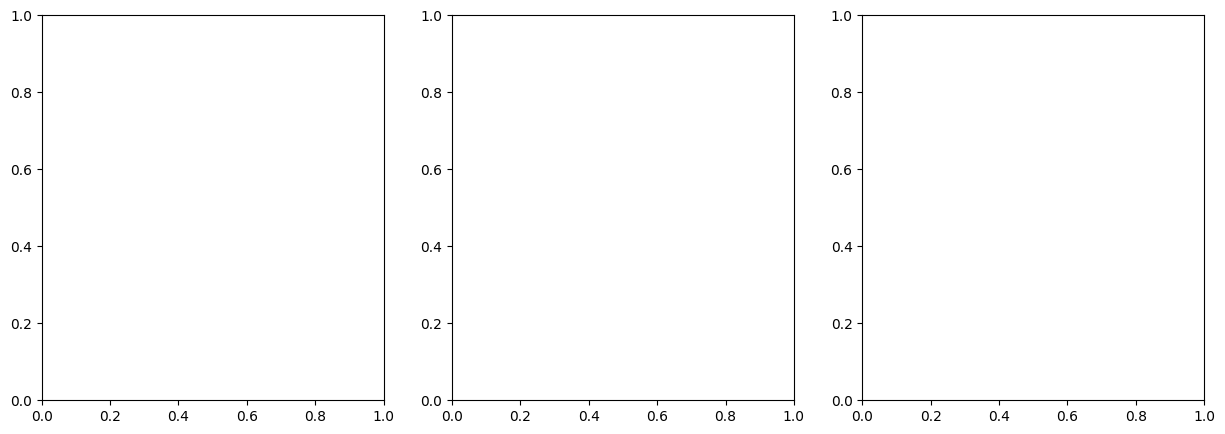

In [14]:
fig1,axes1=plt.subplots(1,3,figsize=(15,5))
fig2,axes2=plt.subplots(1,3,figsize=(15,5))
for i, ax in enumerate(axes1):
    img=cv2.imread(train_data.iloc[i]['filename'])
    ax.set_title(train_data.iloc[i]['label'])
    ax.axis('off')